In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'aarushi_resume-1.pdf',
 'python _copy.pdf',
 'aarushi.1.pdf',
 'Machine (1).pdf',
 'Machine.pdf',
 'DOC-20260426-WA0002..pdf',
 'NOC26CS86S66800036004919693_copy.pdf',
 'PGDDA-SEM-1 Projects-20231129T163346Z-001.zip',
 'PGDDA SEMESTER 2 PROJECTS-20231129T152947Z-001.zip',
 'Ashmeet saggu 00216640621_220725_000205.pdf',
 'Siddharth Sharma (00816640621).pdf',
 'AKANSHA BANSAL_02716640621 (SEM 2_ PGDDA).pdf',
 'AASTHA_TAYAL_MAJOR_PROJECT.pdf',
 '17811071956461349858919647016503.jpg',
 'Machine (1).gdoc',
 'Machine.gdoc',
 'SWELL-KW HRV Dataset - Methodology Flow Spreadsheet.gsheet',
 'FUNDAMENTAL_OF_MATHEMATICAL_STATISTICS_S_C_GUPTA_&_V_K_KAPOOR_compressed.gdoc',
 'Delhi Air Quality Comprehensive Analysis Report (2021-2025).gdoc',
 'Sem-3(aaru',
 'pm25_2021_2025_merged_updated_headers.csv',
 'pm25_forecast_project',
 'aHRV DATSETrchive.zip',
 'LendingClub_Project',
 'SWELL_KW_Project',
 'HRV_Stress_Project',
 'pm25_forecasting_project',
 'loan_project_checkpoints',
 

In [4]:
import os
os.listdir('/content/drive/MyDrive/ML_Project')

['archive.zip', 'online_retail_II.csv']

In [5]:
import pandas as pd

path = "/content/drive/MyDrive/ML_Project/online_retail_II.csv"

df = pd.read_csv(path)
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())

2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [7]:
# Basic info
df.info()

# Missing values
print("\nMissing values:\n", df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Unique customers
print("\nUnique customers:", df['Customer ID'].nunique())

# Unique invoices
print("Unique invoices:", df['Invoice'].nunique())

# Negative Quantity check (returns/cancellations)
print("\nNegative quantity rows:", (df['Quantity'] < 0).sum())

# Negative/zero Price check
print("Negative/zero price rows:", (df['Price'] <= 0).sum())

# Country distribution
print("\nCountry distribution:\n", df['Country'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Missing values:
 Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate rows: 34335

Unique customers: 5942
Unique invoices: 53628

Negative quantity 

In [8]:
# Cancelled invoices generally "C" se start hote hain
cancelled = df[df['Invoice'].astype(str).str.startswith('C')]
print("Cancelled invoice rows:", cancelled.shape[0])
cancelled.head()

Cancelled invoice rows: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [9]:
# Check karo negative quantity waali rows cancelled invoices se match karti hain ya nahi
negative_qty = df[df['Quantity'] < 0]
print("Negative quantity rows:", negative_qty.shape[0])

# Kitni negative-quantity rows "C" invoice ke bahar bhi hain (anomaly check)
non_cancelled_negative = negative_qty[~negative_qty['Invoice'].astype(str).str.startswith('C')]
print("Negative qty but NOT marked cancelled:", non_cancelled_negative.shape[0])
non_cancelled_negative.head()

Negative quantity rows: 22950
Negative qty but NOT marked cancelled: 3457


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

path = "/content/drive/MyDrive/ML_Project/online_retail_II.csv"

df = pd.read_csv(path)

# Step 1: Purchases aur Returns alag karo
returns = df[df['Invoice'].astype(str).str.startswith('C')].copy()
purchases = df[~df['Invoice'].astype(str).str.startswith('C')].copy()

print("Returns:", returns.shape[0])
print("Purchases:", purchases.shape[0])

# Step 2: Return ki quantity ko positive bana do taaki match ho sake
returns['Quantity_abs'] = returns['Quantity'].abs()

# Step 3: Matching key banao (StockCode, Price, Customer ID, Country ke basis par)
match_cols = ['StockCode', 'Price', 'Customer ID', 'Country']

# Step 4: Merge karke matched pairs dhoondo
matched = purchases.merge(
    returns[match_cols + ['Quantity_abs']],
    left_on=match_cols + ['Quantity'],
    right_on=match_cols + ['Quantity_abs'],
    how='inner'
)

print("Matched purchase-return pairs:", matched.shape[0])

Mounted at /content/drive
Returns: 19494
Purchases: 1047877
Matched purchase-return pairs: 15595


In [4]:
# Original index preserve karo taaki baad mein exact rows remove kar sakein
purchases = purchases.reset_index().rename(columns={'index': 'orig_idx_purchase'})
returns = returns.reset_index().rename(columns={'index': 'orig_idx_return'})

purchases['Quantity_abs'] = purchases['Quantity']
returns['Quantity_abs'] = returns['Quantity'].abs()

match_cols = ['StockCode', 'Price', 'Customer ID', 'Country']

# Same group ke andar multiple identical rows ho sakti hain,
# isliye rank use karke ek-ek pair ko unique match karenge (1:1 matching)
purchases['rank'] = purchases.groupby(match_cols + ['Quantity_abs']).cumcount()
returns['rank'] = returns.groupby(match_cols + ['Quantity_abs']).cumcount()

matched = purchases.merge(
    returns[match_cols + ['Quantity_abs', 'rank', 'orig_idx_return']],
    on=match_cols + ['Quantity_abs', 'rank'],
    how='inner'
)

print("Matched pairs (rows):", matched.shape[0])

# Ab exact original indices nikaalo jo remove karni hain
purchase_idx_to_remove = matched['orig_idx_purchase'].tolist()
return_idx_to_remove = matched['orig_idx_return'].tolist()

# Original df se dono (purchase + return) hata do
df_clean = df.drop(index=purchase_idx_to_remove + return_idx_to_remove)

print("Original rows:", df.shape[0])
print("Removed rows:", len(purchase_idx_to_remove) + len(return_idx_to_remove))
print("Remaining rows after return-matching cleanup:", df_clean.shape[0])

Matched pairs (rows): 8258
Original rows: 1067371
Removed rows: 16516
Remaining rows after return-matching cleanup: 1051983


In [5]:
print("Before further cleaning:", df_clean.shape)

# Duplicates remove karo
df_clean = df_clean.drop_duplicates()
print("After removing duplicates:", df_clean.shape)

# Missing Customer ID wali rows remove karo
df_clean = df_clean.dropna(subset=['Customer ID'])
print("After removing missing Customer ID:", df_clean.shape)

Before further cleaning: (1051983, 8)
After removing duplicates: (1018088, 8)
After removing missing Customer ID: (784511, 8)


In [6]:
print("Final clean dataset shape:", df_clean.shape)
df_clean.head()

# Quick sanity check
print("\nRemaining missing values:\n", df_clean.isnull().sum())
print("\nRemaining negative quantity:", (df_clean['Quantity'] < 0).sum())
print("Remaining negative/zero price:", (df_clean['Price'] <= 0).sum())

Final clean dataset shape: (784511, 8)

Remaining missing values:
 Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

Remaining negative quantity: 11684
Remaining negative/zero price: 70


In [7]:
zero_price = df_clean[df_clean['Price'] <= 0]
print(zero_price.shape)
zero_price[['Invoice','StockCode','Description','Quantity','Price']].head(15)

(70, 8)


,Invoice,StockCode,Description,Quantity,Price
4674,489825,22076,6 RIBBONS EMPIRE,12,0.0
6781,489998,48185,DOOR MAT FAIRY CAKE,2,0.0
16107,490727,M,Manual,1,0.0
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,0.0
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,0.0
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,0.0
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,0.0
47126,493761,79320,FLAMINGO LIGHTS,24,0.0
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,0.0
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,0.0


In [8]:
# Test products aur zero-price rows remove karo
df_clean = df_clean[df_clean['Price'] > 0]
print("Shape after removing zero/negative price rows:", df_clean.shape)

Shape after removing zero/negative price rows: (784441, 8)


In [10]:
# Check karo abhi kya dtype hai
print(df_clean['InvoiceDate'].dtype)

# Dobara datetime mein convert karo
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Confirm karo
print(df_clean['InvoiceDate'].dtype)
df_clean['InvoiceDate'].head()

object
datetime64[ns]


,InvoiceDate
0,2009-12-01 07:45:00
1,2009-12-01 07:45:00
2,2009-12-01 07:45:00
3,2009-12-01 07:45:00
4,2009-12-01 07:45:00


In [11]:
# Total Amount column
df_clean['Total'] = df_clean['Quantity'] * df_clean['Price']

# RFM Calculation
import datetime as dt

reference_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
print("Reference date:", reference_date)

rfm = df_clean.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Total', 'sum')
).reset_index()

print("RFM table shape:", rfm.shape)
rfm.head(10)

Reference date: 2011-12-10 12:50:00
RFM table shape: (5923, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346.0,431,15,-51.74
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,5,4404.54
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,9,1889.21
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


In [12]:
negative_monetary = rfm[rfm['Monetary'] <= 0]
print("Customers with Monetary <= 0:", negative_monetary.shape[0])
negative_monetary

Customers with Monetary <= 0: 86


,Customer ID,Recency,Frequency,Monetary
0,12346.0,431,15,-51.74
36,12382.0,682,1,-18.38
156,12503.0,338,2,0.00
357,12706.0,682,1,-91.89
545,12896.0,731,1,-29.75
...,...,...,...,...
5297,17661.0,641,1,-54.00
5391,17755.0,424,1,-72.23
5579,17943.0,680,1,-165.03
5659,18023.0,540,1,-3248.86


In [13]:
rfm_clean = rfm[rfm['Monetary'] > 0].copy()
print("RFM shape before:", rfm.shape)
print("RFM shape after removing non-positive Monetary:", rfm_clean.shape)

rfm_clean.describe()

RFM shape before: (5923, 4)
RFM shape after removing non-positive Monetary: (5837, 4)


,Customer ID,Recency,Frequency,Monetary
count,5837.000000,5837.000000,5837.000000,5837.000000
mean,15319.615042,197.856090,7.250642,2806.330548
std,1714.977802,208.031017,14.898999,13783.689577
min,12347.000000,1.000000,1.000000,1.900000
25%,13838.000000,25.000000,2.000000,337.000000
50%,15321.000000,92.000000,3.000000,847.410000
75%,16801.000000,376.000000,8.000000,2180.280000
max,18287.000000,739.000000,447.000000,570380.610000


In [14]:
def remove_outliers_iqr(data, columns):
    df_out = data.copy()
    outlier_mask = pd.Series(False, index=df_out.index)

    for col in columns:
        Q1 = df_out[col].quantile(0.25)
        Q3 = df_out[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        col_outliers = (df_out[col] < lower_bound) | (df_out[col] > upper_bound)
        print(f"{col}: Lower={lower_bound:.2f}, Upper={upper_bound:.2f}, Outliers={col_outliers.sum()}")

        outlier_mask = outlier_mask | col_outliers

    print(f"\nTotal unique outlier rows (any column): {outlier_mask.sum()}")
    return df_out[~outlier_mask], outlier_mask.sum()

rfm_no_outliers, total_outliers = remove_outliers_iqr(rfm_clean, ['Recency', 'Frequency', 'Monetary'])

print("\nShape before outlier removal:", rfm_clean.shape)
print("Shape after outlier removal:", rfm_no_outliers.shape)

Recency: Lower=-501.50, Upper=902.50, Outliers=0
Frequency: Lower=-7.00, Upper=17.00, Outliers=490
Monetary: Lower=-2427.92, Upper=4945.20, Outliers=622

Total unique outlier rows (any column): 714

Shape before outlier removal: (5837, 4)
Shape after outlier removal: (5123, 4)


In [15]:
from scipy.stats import skew

for col in ['Recency', 'Frequency', 'Monetary']:
    print(f"{col} skewness: {skew(rfm_no_outliers[col]):.3f}")

Recency skewness: 0.750
Frequency skewness: 1.461
Monetary skewness: 1.495


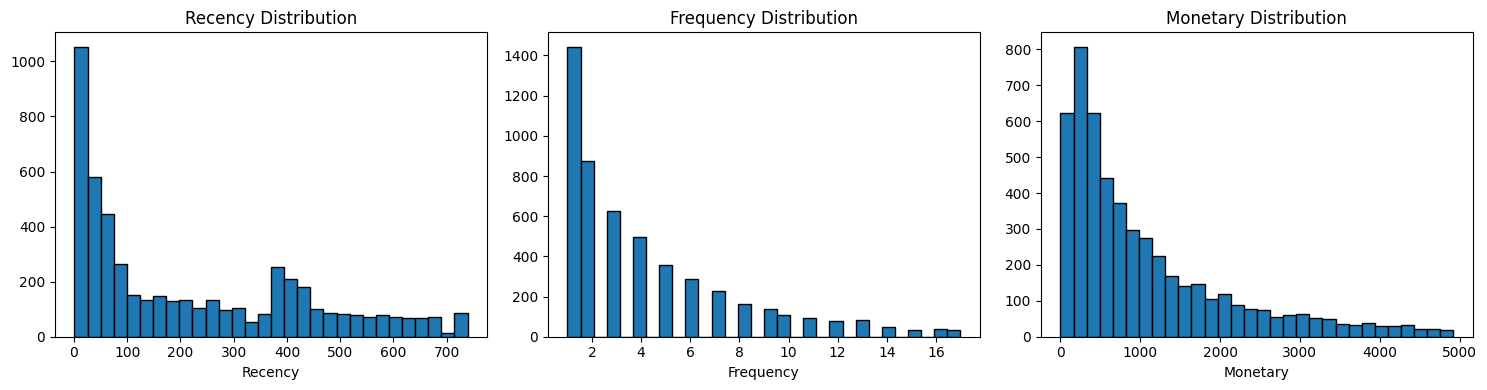

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    axes[i].hist(rfm_no_outliers[col], bins=30, edgecolor='black')
    axes[i].set_title(f'{col} Distribution')
    axes[i].set_xlabel(col)
plt.tight_layout()
plt.show()

In [17]:
import numpy as np
from scipy.stats import skew, boxcox

results = {}

for col in ['Recency', 'Frequency', 'Monetary']:
    original = rfm_no_outliers[col]

    # Log transformation (log(x+1) taaki zero values handle ho jayein)
    log_transformed = np.log1p(original)

    # Square Root transformation
    sqrt_transformed = np.sqrt(original)

    # Box-Cox transformation (requires strictly positive values)
    boxcox_transformed, _ = boxcox(original + 1)  # +1 taaki zero na ho

    results[col] = {
        'Original': skew(original),
        'Log': skew(log_transformed),
        'Sqrt': skew(sqrt_transformed),
        'BoxCox': skew(boxcox_transformed)
    }

comparison_df = pd.DataFrame(results).T
print(comparison_df)

           Original       Log      Sqrt    BoxCox
Recency    0.750069 -0.603260  0.219190 -0.145459
Frequency  1.460624  0.438656  0.788188  0.106919
Monetary   1.494555 -0.362373  0.706256 -0.026011


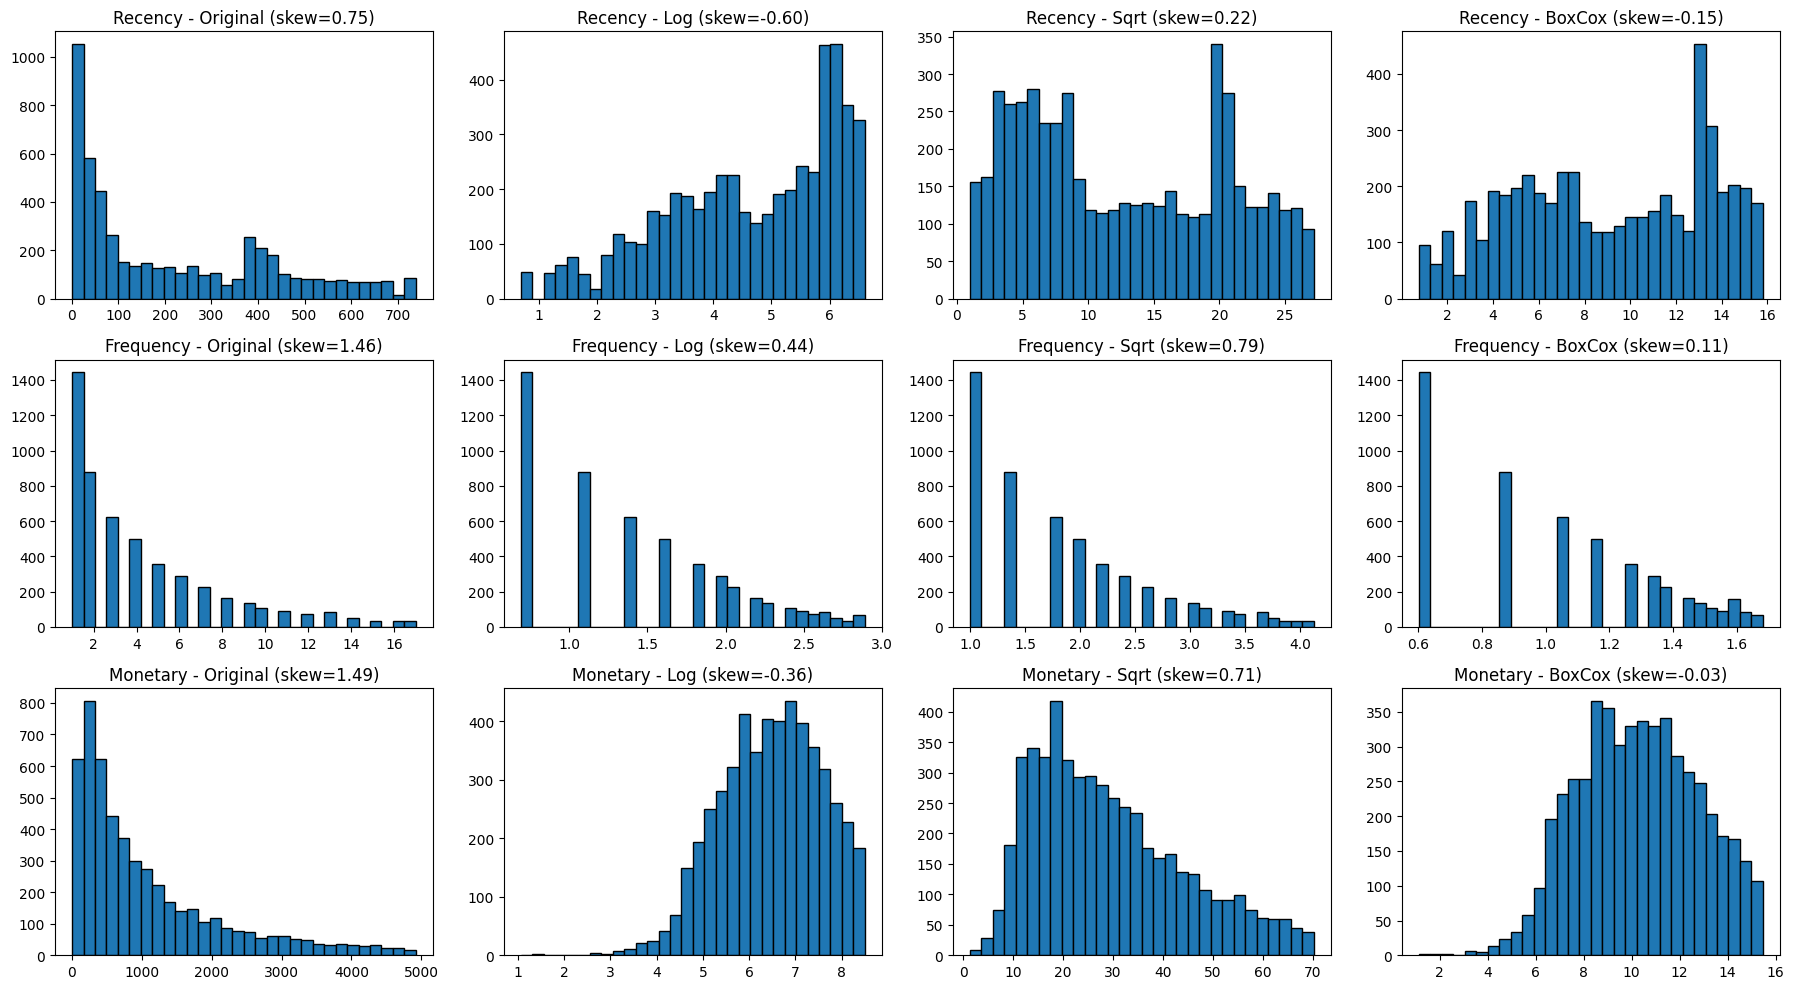

In [18]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))

transformations = {
    'Original': lambda x: x,
    'Log': lambda x: np.log1p(x),
    'Sqrt': lambda x: np.sqrt(x),
    'BoxCox': lambda x: boxcox(x + 1)[0]
}

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    for j, (name, func) in enumerate(transformations.items()):
        transformed = func(rfm_no_outliers[col])
        axes[i, j].hist(transformed, bins=30, edgecolor='black')
        axes[i, j].set_title(f'{col} - {name} (skew={skew(transformed):.2f})')

plt.tight_layout()
plt.show()

In [19]:
from scipy.stats import boxcox

rfm_transformed = rfm_no_outliers.copy()

boxcox_lambdas = {}

for col in ['Recency', 'Frequency', 'Monetary']:
    transformed, lam = boxcox(rfm_transformed[col] + 1)
    rfm_transformed[col + '_BoxCox'] = transformed
    boxcox_lambdas[col] = lam

print("Box-Cox lambda values used:", boxcox_lambdas)
rfm_transformed.head()

Box-Cox lambda values used: {'Recency': np.float64(0.23432469340255613), 'Frequency': np.float64(-0.4155771462093621), 'Monetary': np.float64(0.12902221725214558)}


,Customer ID,Recency,Frequency,Monetary,Recency_BoxCox,Frequency_BoxCox,Monetary_BoxCox
1,12347.0,2,8,4921.53,1.252979,1.440715,15.461251
2,12348.0,75,5,2019.40,7.505847,1.263502,12.941773
3,12349.0,19,5,4404.54,4.343255,1.263502,15.131311
4,12350.0,310,1,334.40,12.111790,0.602248,8.662445
5,12351.0,375,1,300.93,12.856686,0.602248,8.441323


In [20]:
from sklearn.preprocessing import StandardScaler

# Sirf Box-Cox transformed columns use karenge clustering ke liye
features_to_scale = ['Recency_BoxCox', 'Frequency_BoxCox', 'Monetary_BoxCox']

scaler = StandardScaler()
scaled_values = scaler.fit_transform(rfm_transformed[features_to_scale])

rfm_scaled = pd.DataFrame(scaled_values, columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'])
rfm_scaled['Customer ID'] = rfm_transformed['Customer ID'].values

print(rfm_scaled.shape)
rfm_scaled.describe()


(5123, 4)


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled,Customer ID
count,5.123000e+03,5.123000e+03,5.123000e+03,5123.000000
mean,-1.858535e-16,5.166449e-16,9.153976e-17,15340.850673
std,1.000098e+00,1.000098e+00,1.000098e+00,1704.456482
min,-1.999436e+00,-1.269927e+00,-3.663023e+00,12347.000000
25%,-8.667569e-01,-1.269927e+00,-7.305364e-01,13861.500000
50%,2.932009e-02,6.791284e-02,-1.272239e-02,15352.000000
75%,9.438249e-01,8.994761e-01,7.513189e-01,16807.500000
max,1.603579e+00,1.930492e+00,2.075348e+00,18287.000000


In [21]:
!pip install kneed --quiet

In [22]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
import matplotlib.pyplot as plt

X = rfm_scaled[['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled']]

wcss = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

print("WCSS values:", wcss)

WCSS values: [7468.172313486323, 5683.744397787915, 4160.030731283066, 3532.9884399222633, 3042.543583842426, 2807.519013587158, 2574.0080146965734, 2361.5454026900848, 2211.3853011581755]


In [23]:
kneedle = KneeLocator(list(k_range), wcss, curve='convex', direction='decreasing')
optimal_k = kneedle.elbow
print("Optimal K (via KneeLocator):", optimal_k)

Optimal K (via KneeLocator): 4


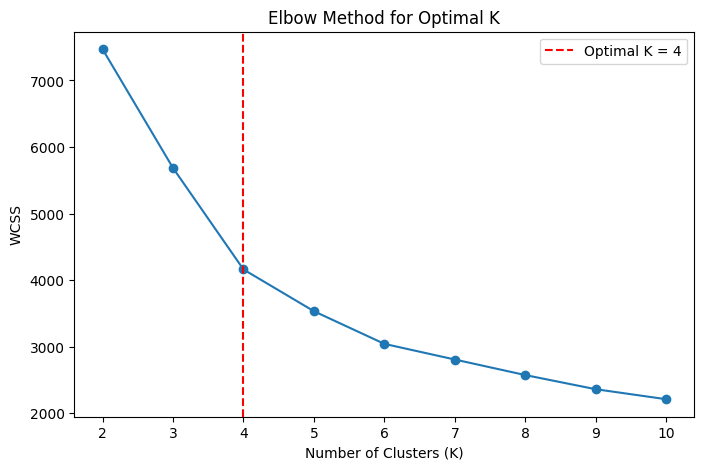

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), wcss, marker='o')
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal K = {optimal_k}')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')
plt.legend()
plt.show()

In [25]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X)

# Cluster labels ko original rfm_no_outliers dataframe mein add karo (interpretable values ke saath)
rfm_final = rfm_no_outliers.reset_index(drop=True).copy()
rfm_final['Cluster'] = cluster_labels

print(rfm_final['Cluster'].value_counts())
rfm_final.head(10)

Cluster
0    1492
2    1408
1    1140
3    1083
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,Cluster
0,12347.0,2,8,4921.53,2
1,12348.0,75,5,2019.40,2
2,12349.0,19,5,4404.54,2
3,12350.0,310,1,334.40,0
4,12351.0,375,1,300.93,0
5,12352.0,36,9,1889.21,2
6,12353.0,204,2,406.76,0
7,12354.0,232,1,1079.40,0
8,12355.0,214,2,947.61,1
9,12358.0,2,5,3887.07,2


In [26]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(X, cluster_labels)
print(f"Silhouette Score for K=4: {sil_score:.4f}")

Silhouette Score for K=4: 0.3791


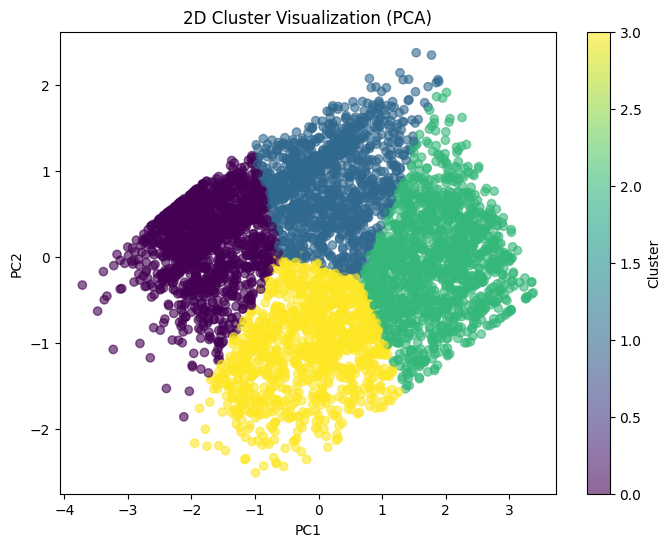

Explained variance ratio: [0.71376005 0.2182583 ]


In [27]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(pca_result[:, 0], pca_result[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D Cluster Visualization (PCA)')
plt.colorbar(scatter, label='Cluster')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

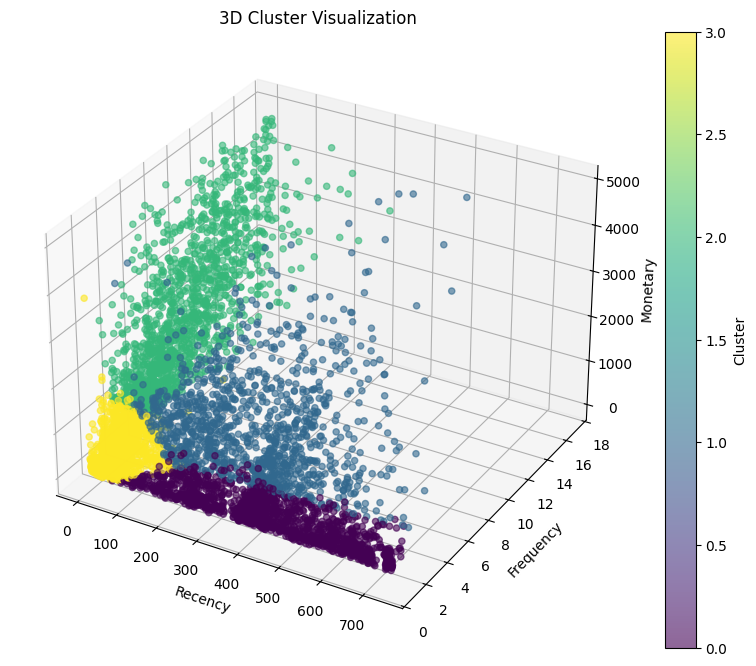

In [28]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    rfm_final['Recency'],
    rfm_final['Frequency'],
    rfm_final['Monetary'],
    c=cluster_labels,
    cmap='viridis',
    alpha=0.6
)

ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')
ax.set_title('3D Cluster Visualization')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [29]:
cluster_profile = rfm_final.groupby('Cluster').agg(
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Customer_Count=('Customer ID', 'count')
).round(2)

print(cluster_profile)

         Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Count
Cluster                                                          
0             441.51           1.31        272.58            1492
1             313.33           4.46       1191.13            1140
2              41.62           8.29       2271.04            1408
3              45.58           2.19        512.26            1083


In [30]:
labels = {
    2: 'Champions',
    1: 'At Risk',
    3: 'New/Occasional',
    0: 'Low Engagement'
}

rfm_final['Segment'] = rfm_final['Cluster'].map(labels)

cluster_profile['Segment'] = cluster_profile.index.map(labels)
print(cluster_profile[['Segment', 'Avg_Recency', 'Avg_Frequency', 'Avg_Monetary', 'Customer_Count']])

                Segment  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Cluster                                                             
0        Low Engagement       441.51           1.31        272.58   
1               At Risk       313.33           4.46       1191.13   
2             Champions        41.62           8.29       2271.04   
3        New/Occasional        45.58           2.19        512.26   

         Customer_Count  
Cluster                  
0                  1492  
1                  1140  
2                  1408  
3                  1083  
